In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder

In [2]:
df = pd.read_csv("D:\\District Development Analyzer\\2011-IndiaStateDistSbDist-0000.xlsx - Data (1).csv")

df.head()

,State,District,Subdistt,Town/Village,Ward,EB,Level,Name,TRU,No_HH,...,MARG_AL_0_3_F,MARG_HH_0_3_P,MARG_HH_0_3_M,MARG_HH_0_3_F,MARG_OT_0_3_P,MARG_OT_0_3_M,MARG_OT_0_3_F,NON_WORK_P,NON_WORK_M,NON_WORK_F
0,0,0,0,0,0,0,India,India,Total,249501663,...,5820403,1420348,491424,928924,5518450,3082613,2435837,728966109,291330383,437635726
1,0,0,0,0,0,0,India,India,Rural,168612897,...,5640822,1154975,386077,768898,3803400,1972348,1831052,485005760,200944045,284061715
2,0,0,0,0,0,0,India,India,Urban,80888766,...,179581,265373,105347,160026,1715050,1110265,604785,243960349,90386338,153574011
3,1,0,0,0,0,0,STATE,JAMMU & KASHMIR,Total,2119718,...,44570,26585,6780,19805,108457,56880,51577,8218589,3445572,4773017
4,1,0,0,0,0,0,STATE,JAMMU & KASHMIR,Rural,1553433,...,40936,21963,5757,16206,89232,45625,43607,5994979,2562471,3432508


In [3]:
print("Shape of Dataset:", df.shape)

df.info()

Shape of Dataset: (19992, 94)
<class 'pandas.DataFrame'>
RangeIndex: 19992 entries, 0 to 19991
Data columns (total 94 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   State           19992 non-null  int64
 1   District        19992 non-null  int64
 2   Subdistt        19992 non-null  int64
 3   Town/Village    19992 non-null  int64
 4   Ward            19992 non-null  int64
 5   EB              19992 non-null  int64
 6   Level           19992 non-null  str  
 7   Name            19992 non-null  str  
 8   TRU             19992 non-null  str  
 9   No_HH           19992 non-null  int64
 10  TOT_P           19992 non-null  int64
 11  TOT_M           19992 non-null  int64
 12  TOT_F           19992 non-null  int64
 13  P_06            19992 non-null  int64
 14  M_06            19992 non-null  int64
 15  F_06            19992 non-null  int64
 16  P_SC            19992 non-null  int64
 17  M_SC            19992 non-null  int64
 18  F_SC   

In [4]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0]

Series([], dtype: int64)

In [5]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [6]:
df = df.drop_duplicates()

print(df.shape)

(19992, 94)


In [7]:
for col in df.columns:
    print(col)

State
District
Subdistt
Town/Village
Ward
EB
Level
Name
TRU
No_HH
TOT_P
TOT_M
TOT_F
P_06
M_06
F_06
P_SC
M_SC
F_SC
P_ST
M_ST
F_ST
P_LIT
M_LIT
F_LIT
P_ILL
M_ILL
F_ILL
TOT_WORK_P
TOT_WORK_M
TOT_WORK_F
MAINWORK_P
MAINWORK_M
MAINWORK_F
MAIN_CL_P
MAIN_CL_M
MAIN_CL_F
MAIN_AL_P
MAIN_AL_M
MAIN_AL_F
MAIN_HH_P
MAIN_HH_M
MAIN_HH_F
MAIN_OT_P
MAIN_OT_M
MAIN_OT_F
MARGWORK_P
MARGWORK_M
MARGWORK_F
MARG_CL_P
MARG_CL_M
MARG_CL_F
MARG_AL_P
MARG_AL_M
MARG_AL_F
MARG_HH_P
MARG_HH_M
MARG_HH_F
MARG_OT_P
MARG_OT_M
MARG_OT_F
MARGWORK_3_6_P
MARGWORK_3_6_M
MARGWORK_3_6_F
MARG_CL_3_6_P
MARG_CL_3_6_M
MARG_CL_3_6_F
MARG_AL_3_6_P
MARG_AL_3_6_M
MARG_AL_3_6_F
MARG_HH_3_6_P
MARG_HH_3_6_M
MARG_HH_3_6_F
MARG_OT_3_6_P
MARG_OT_3_6_M
MARG_OT_3_6_F
MARGWORK_0_3_P
MARGWORK_0_3_M
MARGWORK_0_3_F
MARG_CL_0_3_P
MARG_CL_0_3_M
MARG_CL_0_3_F
MARG_AL_0_3_P
MARG_AL_0_3_M
MARG_AL_0_3_F
MARG_HH_0_3_P
MARG_HH_0_3_M
MARG_HH_0_3_F
MARG_OT_0_3_P
MARG_OT_0_3_M
MARG_OT_0_3_F
NON_WORK_P
NON_WORK_M
NON_WORK_F


In [8]:
columns_map = {

    'TOT_P':'Total_Population',
    'TOT_M':'Male_Population',
    'TOT_F':'Female_Population',

    'P_LIT':'Total_Literates',
    'M_LIT':'Male_Literates',
    'F_LIT':'Female_Literates',

    'P_SC':'SC_Population',
    'P_ST':'ST_Population',

    'TOT_WORK_P':'Total_Workers',
    'TOT_WORK_M':'Male_Workers',
    'TOT_WORK_F':'Female_Workers',

    'NON_WORK_P':'Non_Workers',

    'No_HH':'Number_of_Households',

    'State':'State_Name',
    'District':'District_Name',

    'TRU':'Region_Type'
}

df.rename(columns=columns_map, inplace=True)

In [9]:
df.columns.tolist()

['State_Name',
 'District_Name',
 'Subdistt',
 'Town/Village',
 'Ward',
 'EB',
 'Level',
 'Name',
 'Region_Type',
 'Number_of_Households',
 'Total_Population',
 'Male_Population',
 'Female_Population',
 'P_06',
 'M_06',
 'F_06',
 'SC_Population',
 'M_SC',
 'F_SC',
 'ST_Population',
 'M_ST',
 'F_ST',
 'Total_Literates',
 'Male_Literates',
 'Female_Literates',
 'P_ILL',
 'M_ILL',
 'F_ILL',
 'Total_Workers',
 'Male_Workers',
 'Female_Workers',
 'MAINWORK_P',
 'MAINWORK_M',
 'MAINWORK_F',
 'MAIN_CL_P',
 'MAIN_CL_M',
 'MAIN_CL_F',
 'MAIN_AL_P',
 'MAIN_AL_M',
 'MAIN_AL_F',
 'MAIN_HH_P',
 'MAIN_HH_M',
 'MAIN_HH_F',
 'MAIN_OT_P',
 'MAIN_OT_M',
 'MAIN_OT_F',
 'MARGWORK_P',
 'MARGWORK_M',
 'MARGWORK_F',
 'MARG_CL_P',
 'MARG_CL_M',
 'MARG_CL_F',
 'MARG_AL_P',
 'MARG_AL_M',
 'MARG_AL_F',
 'MARG_HH_P',
 'MARG_HH_M',
 'MARG_HH_F',
 'MARG_OT_P',
 'MARG_OT_M',
 'MARG_OT_F',
 'MARGWORK_3_6_P',
 'MARGWORK_3_6_M',
 'MARGWORK_3_6_F',
 'MARG_CL_3_6_P',
 'MARG_CL_3_6_M',
 'MARG_CL_3_6_F',
 'MARG_AL_3_6_P',


In [10]:
df['Level'].value_counts()

Level
SUB-DISTRICT    17964
DISTRICT         1920
STATE             105
India               3
Name: count, dtype: int64

In [11]:
district_df = df[df['Level'] == 'DISTRICT']

district_df.shape

(1920, 94)

## Feature Engineering

In [12]:
district_df['Literacy_Rate'] = (
    district_df['Total_Literates']
    /
    district_df['Total_Population']
) * 100

In [13]:
district_df['Female_Literacy_Rate'] = (
    district_df['Female_Literates']
    /
    district_df['Female_Population']
) * 100

In [14]:
district_df['Worker_Participation_Rate'] = (
    district_df['Total_Workers']
    /
    district_df['Total_Population']
) * 100

In [15]:
district_df['SC_Percentage'] = (
    district_df['SC_Population']
    /
    district_df['Total_Population']
) * 100

In [16]:
district_df['ST_Percentage'] = (
    district_df['ST_Population']
    /
    district_df['Total_Population']
) * 100

In [17]:
district_df['Gender_Ratio'] = (
    district_df['Female_Population']
    /
    district_df['Male_Population']
) * 1000

In [18]:
district_df['People_Per_Household'] = (
    district_df['Total_Population']
    /
    district_df['Number_of_Households']
)

In [19]:
district_df[[
    'Literacy_Rate',
    'Female_Literacy_Rate',
    'Worker_Participation_Rate',
    'SC_Percentage',
    'ST_Percentage',
    'Gender_Ratio',
    'People_Per_Household'
]].head()

,Literacy_Rate,Female_Literacy_Rate,Worker_Participation_Rate,SC_Percentage,ST_Percentage,Gender_Ratio,People_Per_Household
6,50.514388,39.587393,26.318487,0.120411,8.083148,835.454143,7.639442
7,48.979331,38.523192,25.599086,0.113894,8.945763,858.141725,7.511282
8,61.736482,48.425206,31.577691,0.168053,1.776967,685.046338,8.728144
18,44.530843,35.959112,28.506458,0.048823,3.172426,893.636585,7.292213
19,42.429246,34.445412,27.715592,0.013113,3.551666,909.905791,7.334545


In [20]:
district_df.isnull().sum()

State_Name                    0
District_Name                 0
Subdistt                      0
Town/Village                  0
Ward                          0
                             ..
Worker_Participation_Rate    12
SC_Percentage                12
ST_Percentage                12
Gender_Ratio                 12
People_Per_Household         12
Length: 101, dtype: int64

In [21]:
district_df = district_df.dropna()

In [22]:
final_columns = [

    'State_Name',
    'District_Name',

    'Total_Population',
    'Male_Population',
    'Female_Population',

    'Number_of_Households',

    'Literacy_Rate',
    'Female_Literacy_Rate',

    'Worker_Participation_Rate',

    'SC_Percentage',
    'ST_Percentage',

    'Gender_Ratio',
    'People_Per_Household'
]

district_df = district_df[final_columns]

In [23]:
district_df.describe()

,State_Name,District_Name,Total_Population,Male_Population,Female_Population,Number_of_Households,Literacy_Rate,Female_Literacy_Rate,Worker_Participation_Rate,SC_Percentage,ST_Percentage,Gender_Ratio,People_Per_Household
count,1908.000000,1908.000000,1.908000e+03,1.908000e+03,1.908000e+03,1.908000e+03,1908.000000,1908.000000,1908.000000,1908.000000,1908.000000,1908.000000,1908.000000
mean,17.088050,320.066038,1.269240e+06,6.533231e+05,6.159169e+05,2.615321e+05,64.861225,58.119255,39.604178,14.304938,15.886529,940.666795,4.978808
std,9.392094,184.280200,1.318101e+06,6.828491e+05,6.362098e+05,2.835436e+05,11.129409,13.238349,7.742608,9.014136,26.149316,65.382498,0.739359
min,1.000000,1.000000,9.820000e+02,6.250000e+02,3.570000e+02,1.870000e+02,25.421290,20.859604,24.417807,0.000000,0.000000,340.112454,3.381024
25%,9.000000,161.000000,2.834090e+05,1.467335e+05,1.360288e+05,5.602275e+04,57.008397,48.381933,33.543280,7.673631,0.332657,902.211269,4.444328
50%,18.000000,320.000000,9.257840e+05,4.744960e+05,4.493345e+05,1.889110e+05,65.842015,58.836459,37.907081,14.511689,3.219524,943.495050,4.917269
75%,24.000000,479.000000,1.750198e+06,8.999940e+05,8.469390e+05,3.582350e+05,73.450498,68.152319,45.347958,20.040003,16.639764,979.951618,5.364747
max,35.000000,640.000000,1.106015e+07,5.865078e+06,5.195070e+06,2.529165e+06,89.050474,88.992642,72.183539,53.392996,98.925879,1184.401609,8.728144


In [24]:
district_df.to_csv(
    "cleaned_district_data.csv",
    index=False
)

print("Dataset Saved Successfully")

Dataset Saved Successfully


## EDA

In [25]:
df = pd.read_csv("cleaned_district_data.csv")

df.head()

,State_Name,District_Name,Total_Population,Male_Population,Female_Population,Number_of_Households,Literacy_Rate,Female_Literacy_Rate,Worker_Participation_Rate,SC_Percentage,ST_Percentage,Gender_Ratio,People_Per_Household
0,1,1,870354,474190,396164,113929,50.514388,39.587393,26.318487,0.120411,8.083148,835.454143,7.639442
1,1,1,765625,412038,353587,101930,48.979331,38.523192,25.599086,0.113894,8.945763,858.141725,7.511282
2,1,1,104729,62152,42577,11999,61.736482,48.425206,31.577691,0.168053,1.776967,685.046338,8.728144
3,1,2,753745,398041,355704,103363,44.530843,35.959112,28.506458,0.048823,3.172426,893.636585,7.292213
4,1,2,655833,343385,312448,89417,42.429246,34.445412,27.715592,0.013113,3.551666,909.905791,7.334545


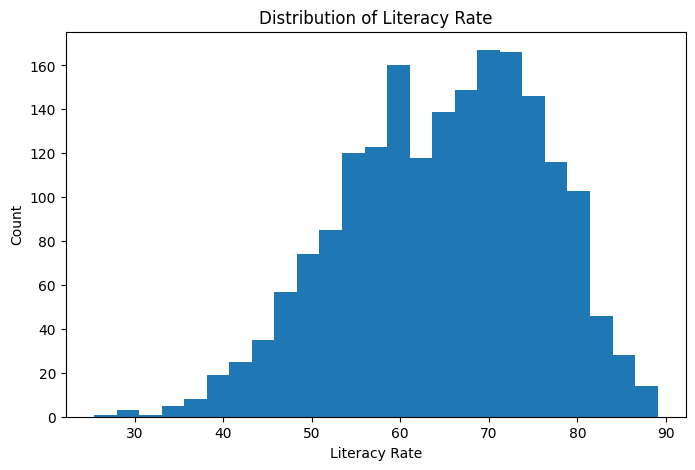

In [26]:
plt.figure(figsize=(8,5))

plt.hist(df['Literacy_Rate'], bins=25)

plt.xlabel("Literacy Rate")
plt.ylabel("Count")
plt.title("Distribution of Literacy Rate")

plt.show()

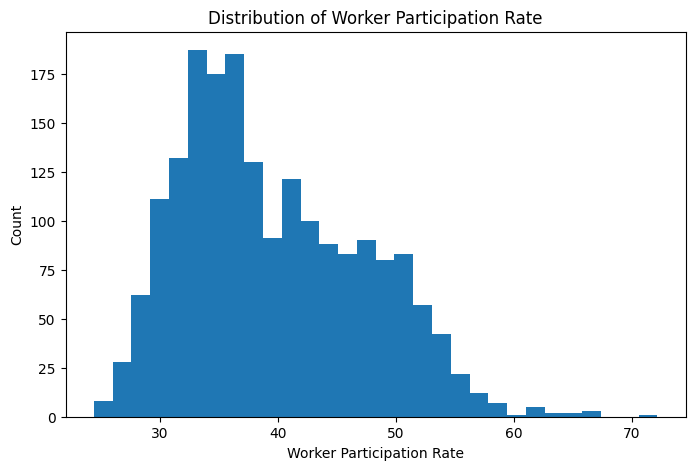

In [27]:
plt.figure(figsize=(8,5))

plt.hist(df['Worker_Participation_Rate'], bins=30)

plt.xlabel("Worker Participation Rate")
plt.ylabel("Count")
plt.title("Distribution of Worker Participation Rate")

plt.show()

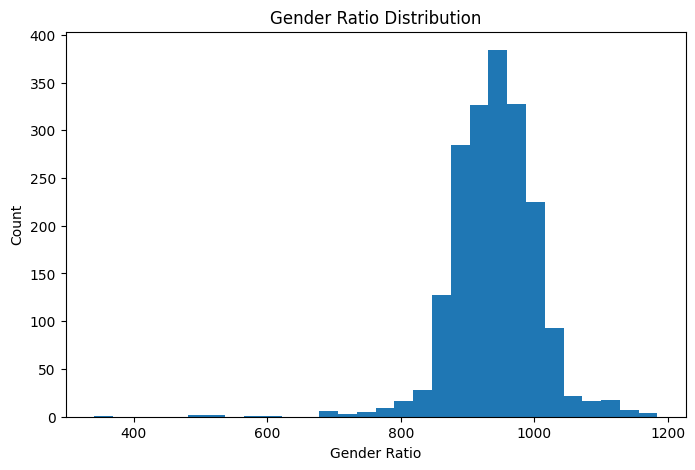

In [28]:
plt.figure(figsize=(8,5))

plt.hist(df['Gender_Ratio'], bins=30)

plt.xlabel("Gender Ratio")
plt.ylabel("Count")
plt.title("Gender Ratio Distribution")

plt.show()

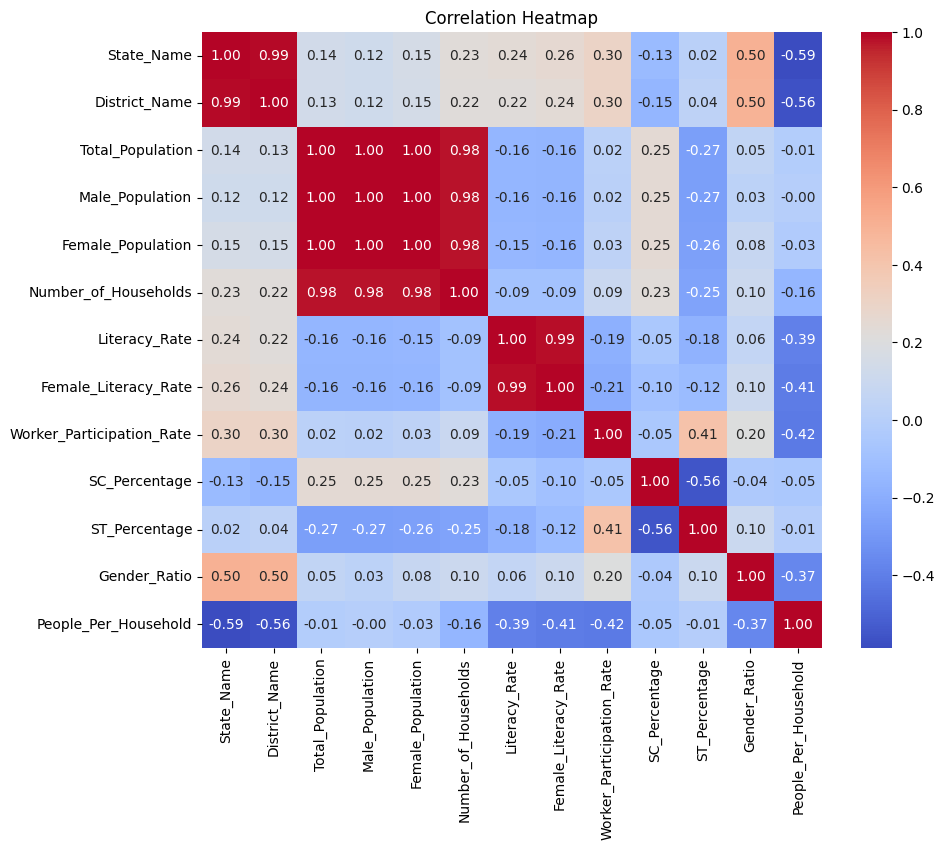

In [29]:
plt.figure(figsize=(10,8))

corr = df.corr(numeric_only=True)

sns.heatmap(corr,
            annot=True,
            cmap='coolwarm',
            fmt=".2f")

plt.title("Correlation Heatmap")

plt.show()

In [30]:
top10 = df.sort_values(
    by='Literacy_Rate',
    ascending=False
).head(10)

top10[['District_Name','Literacy_Rate']]

,District_Name,Literacy_Rate
1788,599,89.050474
1782,597,88.968735
1786,599,88.737460
1787,599,88.698807
1780,597,88.617514
1781,597,88.476594
1895,636,87.215420
1896,636,87.215420
1776,595,87.150924
1785,598,87.125418


In [31]:
bottom10 = df.sort_values(
    by='Literacy_Rate'
).head(10)

bottom10[['District_Name','Literacy_Rate']]

,District_Name,Literacy_Rate
1388,465,25.421290
1241,416,28.664739
1387,465,28.772879
1244,417,30.158224
1385,464,30.676427
1243,417,34.055166
1384,464,34.347757
1238,415,34.377389
1316,441,34.959198
1187,398,35.061354


In [32]:
top_worker = df.sort_values(
    by='Worker_Participation_Rate',
    ascending=False
).head(10)

top_worker[['District_Name','Worker_Participation_Rate']]

,District_Name,Worker_Participation_Rate
730,245,72.183539
98,34,66.895306
99,34,66.895306
808,271,66.345178
798,268,64.558793
806,271,64.472427
807,271,64.155276
75,26,63.592022
777,261,62.398525
783,263,61.995405


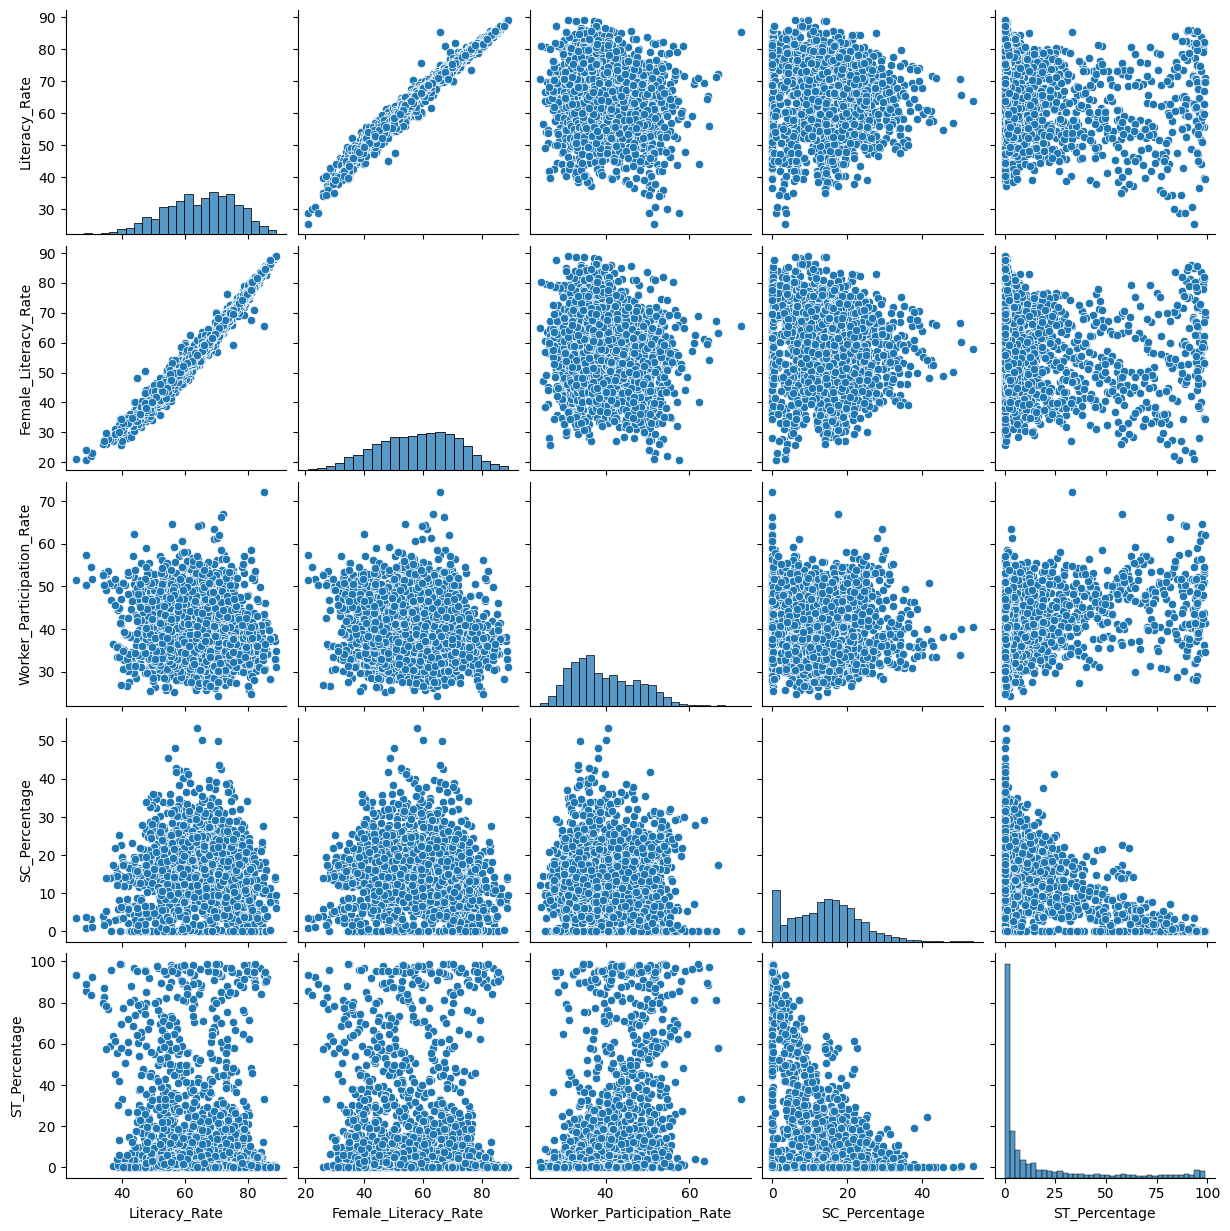

In [33]:
sns.pairplot(df[[
    'Literacy_Rate',
    'Female_Literacy_Rate',
    'Worker_Participation_Rate',
    'SC_Percentage',
    'ST_Percentage'
]])

plt.show()

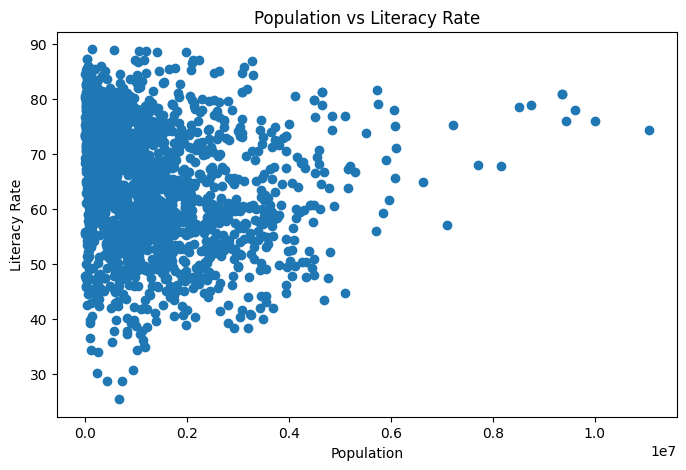

In [34]:
plt.figure(figsize=(8,5))

plt.scatter(
    df['Total_Population'],
    df['Literacy_Rate']
)

plt.xlabel("Population")
plt.ylabel("Literacy Rate")

plt.title("Population vs Literacy Rate")

plt.show()

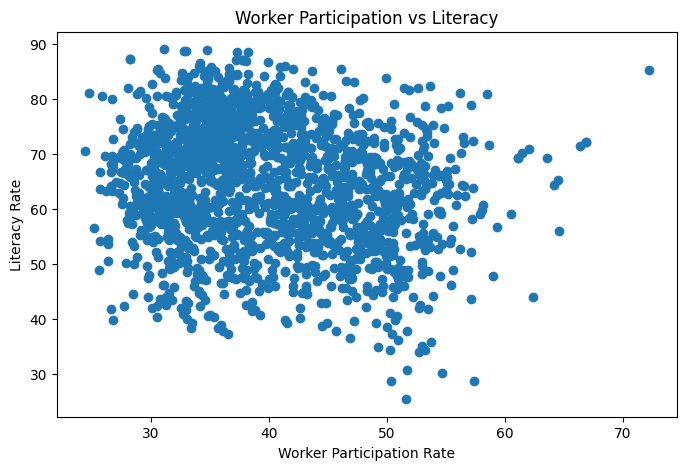

In [35]:
plt.figure(figsize=(8,5))

plt.scatter(
    df['Worker_Participation_Rate'],
    df['Literacy_Rate']
)

plt.xlabel("Worker Participation Rate")
plt.ylabel("Literacy Rate")

plt.title("Worker Participation vs Literacy")

plt.show()

In [36]:
df.to_csv(
    "EDA_Dataset.csv",
    index=False
)

print("EDA Completed Successfully!")

EDA Completed Successfully!


## Target Variable Creation

In [37]:
df[['Literacy_Rate',
    'Female_Literacy_Rate',
    'Worker_Participation_Rate']].describe()

,Literacy_Rate,Female_Literacy_Rate,Worker_Participation_Rate
count,1908.000000,1908.000000,1908.000000
mean,64.861225,58.119255,39.604178
std,11.129409,13.238349,7.742608
min,25.421290,20.859604,24.417807
25%,57.008397,48.381933,33.543280
50%,65.842015,58.836459,37.907081
75%,73.450498,68.152319,45.347958
max,89.050474,88.992642,72.183539


In [38]:
df['Household_Score'] = (
    1 / df['People_Per_Household']
)

df['Household_Score'] *= 100

In [39]:
df['Dependency_Rate'] = (
    100 - df['Worker_Participation_Rate']
)

In [40]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

cols = [
    'Literacy_Rate',
    'Female_Literacy_Rate',
    'Worker_Participation_Rate',
    'Gender_Ratio',
    'Household_Score',
    'Dependency_Rate'
]

df[cols] = scaler.fit_transform(df[cols])

In [41]:
df['Development_Score'] = (

      0.35 * df['Literacy_Rate']

    + 0.20 * df['Female_Literacy_Rate']

    + 0.20 * df['Worker_Participation_Rate']

    + 0.10 * df['Gender_Ratio']

    + 0.10 * df['Household_Score']

    - 0.05 * df['Dependency_Rate']

)

In [42]:
df['Development_Score'] = (
    df['Development_Score'] - df['Development_Score'].min()
) / (
    df['Development_Score'].max() -
    df['Development_Score'].min()
)

df['Development_Score'] *= 100

In [43]:
def categorize(score):

    if score >= 70:
        return "Highly Developed"

    elif score >= 45:
        return "Developing"

    else:
        return "Underdeveloped"

df['Development_Category'] = df['Development_Score'].apply(categorize)

In [44]:
df['Development_Category'].value_counts()

Development_Category
Developing          797
Highly Developed    570
Underdeveloped      541
Name: count, dtype: int64

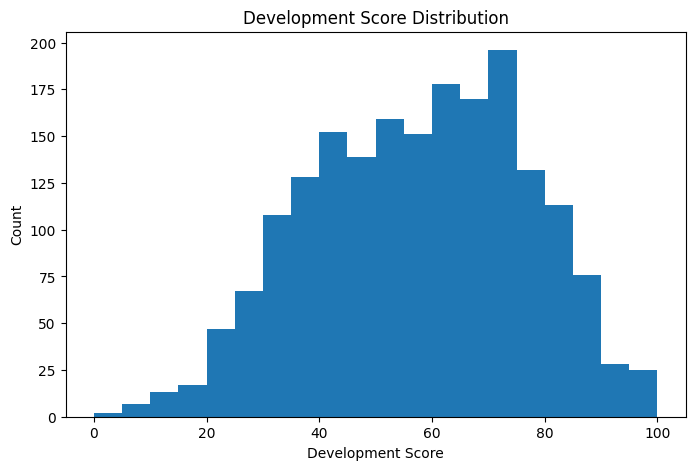

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(
    df['Development_Score'],
    bins=20
)

plt.xlabel("Development Score")
plt.ylabel("Count")
plt.title("Development Score Distribution")

plt.show()

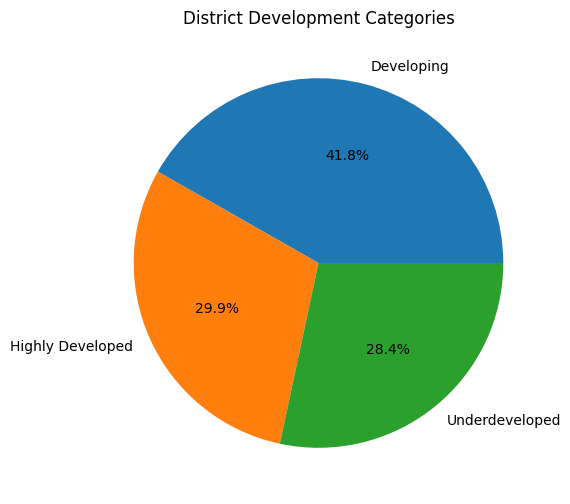

In [46]:
counts = df['Development_Category'].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    counts,
    labels=counts.index,
    autopct="%1.1f%%"
)

plt.title("District Development Categories")

plt.show()

In [47]:
df.to_csv(
    "district_development_dataset.csv",
    index=False
)

print("Dataset Saved Successfully")

Dataset Saved Successfully


## Machine Learning


In [48]:
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    classification_report,
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

import joblib

In [49]:
le = LabelEncoder()

df['Development_Category_Encoded'] = le.fit_transform(
    df['Development_Category']
)

df[['Development_Category',
    'Development_Category_Encoded']].head()

,Development_Category,Development_Category_Encoded
0,Underdeveloped,2
1,Underdeveloped,2
2,Underdeveloped,2
3,Underdeveloped,2
4,Underdeveloped,2


In [50]:
print(dict(zip(
    le.classes_,
    le.transform(le.classes_)
)))

{'Developing': np.int64(0), 'Highly Developed': np.int64(1), 'Underdeveloped': np.int64(2)}


In [51]:
features = [

    'Literacy_Rate',
    'Female_Literacy_Rate',
    'Worker_Participation_Rate',

    'SC_Percentage',
    'ST_Percentage',

    'Gender_Ratio',
    'People_Per_Household'

]

X = df[features]

y = df['Development_Category_Encoded']

In [52]:
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.2,

    random_state=42,

    stratify=y
)

In [53]:
print(X_train.shape)
print(X_test.shape)

(1526, 7)
(382, 7)


#### Model1:Logistic regression

In [54]:
lr = LogisticRegression(
    max_iter=1000
)

lr.fit(
    X_train,
    y_train
)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [55]:
y_pred_lr = lr.predict(X_test)

print(
    "Accuracy:",
    accuracy_score(
        y_test,
        y_pred_lr
    )
)

Accuracy: 0.918848167539267


In [56]:
print(
    classification_report(
        y_test,
        y_pred_lr
    )
)

              precision    recall  f1-score   support

           0       0.90      0.91      0.90       160
           1       0.93      0.96      0.94       114
           2       0.94      0.89      0.91       108

    accuracy                           0.92       382
   macro avg       0.92      0.92      0.92       382
weighted avg       0.92      0.92      0.92       382



#### Decision Tree

In [57]:
dt = DecisionTreeClassifier(
    random_state=42
)

dt.fit(
    X_train,
    y_train
)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

In [58]:
y_pred_dt = dt.predict(X_test)

print(
    "Accuracy:",
    accuracy_score(
        y_test,
        y_pred_dt
    )
)

Accuracy: 0.9057591623036649


In [59]:
print(
    classification_report(
        y_test,
        y_pred_dt
    )
)

              precision    recall  f1-score   support

           0       0.91      0.86      0.88       160
           1       0.93      0.96      0.95       114
           2       0.88      0.91      0.89       108

    accuracy                           0.91       382
   macro avg       0.91      0.91      0.91       382
weighted avg       0.91      0.91      0.91       382



#### Random Forest

In [60]:
rf = RandomForestClassifier(

    n_estimators=200,

    random_state=42
)

rf.fit(
    X_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [61]:
y_pred_rf = rf.predict(X_test)

print(
    "Accuracy:",
    accuracy_score(
        y_test,
        y_pred_rf
    )
)

Accuracy: 0.9554973821989529


In [62]:
print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

              precision    recall  f1-score   support

           0       0.96      0.94      0.95       160
           1       0.97      0.97      0.97       114
           2       0.94      0.96      0.95       108

    accuracy                           0.96       382
   macro avg       0.96      0.96      0.96       382
weighted avg       0.96      0.96      0.96       382



In [63]:
results = {

    "Logistic Regression":
    accuracy_score(
        y_test,
        y_pred_lr
    ),

    "Decision Tree":
    accuracy_score(
        y_test,
        y_pred_dt
    ),

    "Random Forest":
    accuracy_score(
        y_test,
        y_pred_rf
    )
}

results

{'Logistic Regression': 0.918848167539267,
 'Decision Tree': 0.9057591623036649,
 'Random Forest': 0.9554973821989529}

In [64]:
joblib.dump(
    rf,
    "development_model.pkl"
)

joblib.dump(
    le,
    "label_encoder.pkl"
)

print("Model Saved")

Model Saved


In [65]:
importance = pd.DataFrame({

    'Feature': features,

    'Importance':
    rf.feature_importances_

})

importance.sort_values(
    by='Importance',
    ascending=False
)

,Feature,Importance
0,Literacy_Rate,0.303558
1,Female_Literacy_Rate,0.253168
6,People_Per_Household,0.154819
2,Worker_Participation_Rate,0.152596
5,Gender_Ratio,0.055751
4,ST_Percentage,0.047935
3,SC_Percentage,0.032173


In [66]:
importance = pd.DataFrame({
    'Feature': features,
    'Importance': rf.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance)

                     Feature  Importance
0              Literacy_Rate    0.303558
1       Female_Literacy_Rate    0.253168
6       People_Per_Household    0.154819
2  Worker_Participation_Rate    0.152596
5               Gender_Ratio    0.055751
4              ST_Percentage    0.047935
3              SC_Percentage    0.032173


## Literacy Prediction


In [67]:
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import pandas as pd

In [68]:
features = [

    'Total_Population',

    'Number_of_Households',

    'Worker_Participation_Rate',

    'SC_Percentage',

    'ST_Percentage',

    'Gender_Ratio',

    'People_Per_Household'

]

X = district_df[features]

y = district_df['Literacy_Rate']

In [69]:
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.2,

    random_state=42
)

In [70]:
lr = LinearRegression()

lr.fit(
    X_train,
    y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [71]:
pred_lr = lr.predict(X_test)

print("MAE:",
      mean_absolute_error(
          y_test,
          pred_lr
      ))

print("RMSE:",
      np.sqrt(
          mean_squared_error(
              y_test,
              pred_lr
          )
      ))

print("R2 Score:",
      r2_score(
          y_test,
          pred_lr
      ))

MAE: 6.737579384570862
RMSE: 8.795605162747506
R2 Score: 0.3296580205825883


In [72]:
rf = RandomForestRegressor(

    n_estimators=200,

    random_state=42
)

rf.fit(
    X_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [73]:
pred_rf = rf.predict(X_test)

print("MAE:",
      mean_absolute_error(
          y_test,
          pred_rf
      ))

print("RMSE:",
      np.sqrt(
          mean_squared_error(
              y_test,
              pred_rf
          )
      ))

print("R2 Score:",
      r2_score(
          y_test,
          pred_rf
      ))

MAE: 4.698589412718853
RMSE: 6.243146081453065
R2 Score: 0.6622681955766925


In [74]:
import joblib

joblib.dump(
    rf,
    "literacy_prediction_model.pkl"
)

print("Model Saved")

Model Saved


In [75]:
df.groupby('Development_Category')[
    [
        'Literacy_Rate',
        'Female_Literacy_Rate',
        'Worker_Participation_Rate'
    ]
].mean()

,Literacy_Rate,Female_Literacy_Rate,Worker_Participation_Rate
Development_Category,,,
Developing,0.624743,0.548451,0.321639
Highly Developed,0.796200,0.745454,0.364634
Underdeveloped,0.426803,0.335299,0.263273


In [76]:
df[
[
'Literacy_Rate',
'Female_Literacy_Rate',
'Worker_Participation_Rate'
]
].describe()

,Literacy_Rate,Female_Literacy_Rate,Worker_Participation_Rate
count,1908.000000,1908.000000,1908.000000
mean,0.619840,0.546866,0.317934
std,0.174910,0.194301,0.162095
min,0.000000,0.000000,0.000000
25%,0.496425,0.403950,0.191046
50%,0.635254,0.557393,0.282405
75%,0.754830,0.694123,0.438183
max,1.000000,1.000000,1.000000


In [77]:
df[
[
'SC_Percentage',
'ST_Percentage',
'Gender_Ratio',
'People_Per_Household'
]
].describe()

,SC_Percentage,ST_Percentage,Gender_Ratio,People_Per_Household
count,1908.000000,1908.000000,1908.000000,1908.000000
mean,14.304938,15.886529,0.711314,4.978808
std,9.014136,26.149316,0.077441,0.739359
min,0.000000,0.000000,0.000000,3.381024
25%,7.673631,0.332657,0.665766,4.444328
50%,14.511689,3.219524,0.714663,4.917269
75%,20.040003,16.639764,0.757844,5.364747
max,53.392996,98.925879,1.000000,8.728144


In [78]:
df['Literacy_Rate'].describe()

count    1908.000000
mean        0.619840
std         0.174910
min         0.000000
25%         0.496425
50%         0.635254
75%         0.754830
max         1.000000
Name: Literacy_Rate, dtype: float64